# Proyecto Final: Predicción de Fuga de Clientes
El operador de telecomunicaciones **Interconnect** busca reducir la cancelación de clientes (`Churn`) mediante un sistema que identifique con anticipación a quienes podrían darse de baja, para ofrecerles promociones y planes especiales.

**Objetivo:** Desarrollar y comparar modelos capaces de predecir si un cliente se dará de baja próximamente (Sí/No).
- El modelo se evaluará principalmente con AUC-ROC y con Recall como métrica adicional.

## Etapa 1: Plan de Trabajo
*Escribe aquí tu plan de trabajo inicial. Aborda brevemente:*
1. *¿Cómo planeas unir los datos y qué harás con los valores nulos generados?*
    - Los 4 conjuntos tienen **customerID**, el cual usare para unir los 4 en un solo conjunto.
    - Voy a trabajar los valores nulos como -1, ya que con el 0 estan marcados servicios que si se tienen pero no se usan.
2. *¿Cuál será tu variable objetivo y qué tipo de problema de Machine Learning resolverás?*
    - Modificare la columna de **EndDate** para que muestre 0 para los que tienen fecha y 1 para los que no (los activos tienen 1).
    - Esto sera un problema de regresión y usare sigmoide para la neurona de salida.
3. *¿Qué pasos de preprocesamiento (codificación categórica, fechas, etc.) consideras necesarios y sobre que variables?*
    - Categorical encoding ya que muchas variables son de tipo object, pero algunas de esas que si son variables numericas solo hay que cambiaslas a float.
4. *¿Qué modelos planeas entrenar?*
    - Logistic Regression, Random Forest, XGBoost y Neural Network.

## Etapa 2: Código de Solución

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from sklearn.utils.class_weight import compute_class_weight

from xgboost import XGBClassifier

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC

import tensorflow as tf

seed = 1234

### 1. Exploración de Datos (EDA)
*Carga de datos, análisis de distribuciones, identificación de anomalías.*

In [2]:
contract = pd.read_csv("/datasets/final_provider/contract.csv")
personal = pd.read_csv("/datasets/final_provider/personal.csv")
internet = pd.read_csv("/datasets/final_provider/internet.csv")
phone = pd.read_csv("/datasets/final_provider/phone.csv")

In [3]:
for dataset in [contract, personal, internet, phone]:
    print("\n", dataset.info())
    display(dataset.sample())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB

 None


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
6121,7337-CINUD,2019-06-01,No,Two year,No,Bank transfer (automatic),19.5,159.35


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB

 None


,customerID,gender,SeniorCitizen,Partner,Dependents
6923,7619-PLRLP,Female,0,Yes,No


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB

 None


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
1409,7530-HDYDS,Fiber optic,No,Yes,Yes,Yes,No,No


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB

 None


,customerID,MultipleLines
376,7663-ZTEGJ,Yes


### 2. Preprocesamiento e Ingeniería de Características
*Procesar valores nulos, creación de la variable objetivo, codificación de variables categóricas (justifica tu elección de método).*
*Pista: Los modelos predictivos no entienden de fechas en formato texto. ¿Cómo puedes transformar las fechas de inicio y fin en una variable numérica útil para el modelo?*

In [4]:
# Union de tablas por "customerID"
df_join = pd.merge(contract, personal, how='outer', on='customerID')
df_join = pd.merge(df_join, internet, how='outer', on='customerID')
df_join = pd.merge(df_join, phone, how='outer', on='customerID')

display(df_join.sample().T)
print(df_join.info())

,372
customerID,6122-EFVKN
BeginDate,2018-02-01
EndDate,No
Type,Two year
PaperlessBilling,No
PaymentMethod,Mailed check
MonthlyCharges,35.75
TotalCharges,830.8
gender,Male
SeniorCitizen,0


<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
 8   gender            7043 non-null   object 
 9   SeniorCitizen     7043 non-null   int64  
 10  Partner           7043 non-null   object 
 11  Dependents        7043 non-null   object 
 12  InternetService   5517 non-null   object 
 13  OnlineSecurity    5517 non-null   object 
 14  OnlineBackup      5517 non-null   object 
 15  DeviceProtection  5517 non-null   object 
 16  TechSupport       5517 non-null   object 


In [5]:
for col in df_join.select_dtypes(include=["object", "category"]).columns:
    print(col, df_join[col].unique())

customerID ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
BeginDate ['2020-01-01' '2017-04-01' '2019-10-01' '2016-05-01' '2019-09-01'
 '2019-03-01' '2018-04-01' '2019-04-01' '2017-07-01' '2014-12-01'
 '2019-01-01' '2018-10-01' '2015-04-01' '2015-09-01' '2018-01-01'
 '2014-05-01' '2015-10-01' '2014-03-01' '2018-05-01' '2019-11-01'
 '2019-02-01' '2016-01-01' '2017-08-01' '2015-12-01' '2014-02-01'
 '2018-06-01' '2019-12-01' '2017-11-01' '2019-06-01' '2016-04-01'
 '2017-02-01' '2018-12-01' '2014-04-01' '2018-09-01' '2014-11-01'
 '2016-07-01' '2015-02-01' '2018-07-01' '2014-08-01' '2016-03-01'
 '2018-08-01' '2014-10-01' '2015-06-01' '2016-08-01' '2019-05-01'
 '2017-03-01' '2016-02-01' '2017-09-01' '2014-09-01' '2017-12-01'
 '2016-12-01' '2017-06-01' '2015-05-01' '2016-10-01' '2016-09-01'
 '2019-08-01' '2019-07-01' '2017-05-01' '2017-10-01' '2014-07-01'
 '2018-03-01' '2015-01-01' '2018-11-01' '2015-03-01' '2018-02-01'
 '2016-06-01' '2015-08-01' '2015-11-

In [6]:
# Churn como variable objetivo
df_join["Churn"] = (df_join["EndDate"] != "No").astype(int)


# Cargos a variable numerica
df_join["TotalCharges"] = pd.to_numeric(df_join["TotalCharges"], errors="coerce")


# Columnas con datos binarios
binary_cols = [
    "PaperlessBilling", "Partner", "Dependents",
    "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "MultipleLines",
]
for col in binary_cols:
    df_join[col] = df_join[col].map({"Yes": 1, "No": 0})


# Gender a binario
df_join["gender"] = df_join["gender"].map({
    "Male": 0,
    "Female": 1
})

In [7]:
# Fecha de inicio máxima
df_join['BeginDate'] = pd.to_datetime(df_join['BeginDate'])
begin_max = df_join['BeginDate'].max()

# Fechas de inicio de contratos de usuarios que aun no tienen cargos
no_charges_yet = df_join[df_join['TotalCharges'].isna()]['BeginDate'].unique()

# Fecha maxima de end date
end_max = df_join[df_join['EndDate'] != 'No']['EndDate'].max()

print(begin_max, no_charges_yet, end_max)

2020-02-01 00:00:00 ['2020-02-01T00:00:00.000000000'] 2020-01-01 00:00:00


- La máxima fecha de inicio es 2020-02-01
- Los usuarios que aun no tienen cargos iniciaron en 2020-02-01
- La ultima fecha donde un usuario cancelo, fue 2020-01-01 (un mes antes)

*Usare 2020-02-01 como fecha actual, ya que los usuarios que aun no tienen cargos es muy probable que sea porque son usuarios que aun no cumplen el mes y esto no afecha a la máxima de end date, porque es posterior*


In [8]:
# Usare 2020-02-01 como fecha actual y por lo tanto la antigüedad (tenure) sera calculada restandole BeginDate
df, cut_date = df_join.copy(), begin_max
df['tenure'] = cut_date - df['BeginDate']
df['tenure'] = df['tenure'].dt.days.astype(int)

print(df['tenure'].isna().sum())

0



### 3. Selección de Variables y Entrenamiento de Modelos (Baseline)
*Entrena al menos dos modelos distintos sin aplicar técnicas de balanceo de clases. Evalúa su AUC-ROC y Recall.*



In [9]:
features = df.drop(['customerID', 'Churn', 'EndDate', 'BeginDate'], axis=1).copy()
target = df['Churn']

In [10]:
# Primera división
train_features, temp_features, train_target, temp_target = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=seed,
    stratify=target
)

# Segunda división del conjunto de datos
valid_features, test_features, valid_target, test_target = train_test_split(
    temp_features,
    temp_target,
    test_size=0.5,
    random_state=seed,
    stratify=temp_target
)

# Generar copias
train_features = train_features.copy()
valid_features = valid_features.copy()
test_features = test_features.copy()

### One-Hot encoding

In [11]:
# Columnas con datos categoricos
categorical_cols = [
    "Type",
    "PaymentMethod",
    "InternetService",
    "MultipleLines"
]

# Crear codificador
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse=False
)
encoder.fit(train_features[categorical_cols])

# Aplicar One-Hot Encoding a los tres DataFrames
for df in [train_features, valid_features, test_features]:
    encoded = pd.DataFrame(
        encoder.transform(df[categorical_cols]),
        columns=encoder.get_feature_names(categorical_cols),
        index=df.index
    )

    df[encoded.columns] = encoded
    df.drop(columns=categorical_cols, inplace=True)

In [12]:
train_features.isna().sum()[train_features.isna().sum()>0]

TotalCharges           8
OnlineSecurity      1224
OnlineBackup        1224
DeviceProtection    1224
TechSupport         1224
StreamingTV         1224
StreamingMovies     1224
dtype: int64

In [13]:
for df in [train_features, valid_features, test_features]:
    df[[
        'OnlineSecurity', 
        'OnlineBackup', 
        'DeviceProtection', 
        'TechSupport', 
        'StreamingTV', 
        'StreamingMovies'
       ]] = df[['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']].fillna(0)
    df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [14]:
# verificamos si aun hay nulos
print(train_features.isna().sum()[train_features.isna().sum()>0])

print(train_features.info())

Series([], dtype: int64)
<class 'pandas.core.frame.DataFrame'>
Int64Index: 5634 entries, 4029 to 102
Data columns (total 27 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   PaperlessBilling                         5634 non-null   int64  
 1   MonthlyCharges                           5634 non-null   float64
 2   TotalCharges                             5634 non-null   float64
 3   gender                                   5634 non-null   int64  
 4   SeniorCitizen                            5634 non-null   int64  
 5   Partner                                  5634 non-null   int64  
 6   Dependents                               5634 non-null   int64  
 7   OnlineSecurity                           5634 non-null   float64
 8   OnlineBackup                             5634 non-null   float64
 9   DeviceProtection                         5634 non-null   float64
 10  TechSupport          

### Escalado de valores

In [15]:
# Crear objeto
scaler = StandardScaler()

# Columnas a escalar
scaler_columns = ['MonthlyCharges', 'TotalCharges', 'tenure']

# Ajustar y trasnformar
train_features[scaler_columns] =  scaler.fit_transform(
    train_features[scaler_columns]
)

In [16]:
# Transformar conjunto de validación
valid_features[scaler_columns] =  scaler.transform(
    valid_features[scaler_columns]
)

# Transformar conjunto de prueba
test_features[scaler_columns] =  scaler.transform(
    test_features[scaler_columns]
)

### Entrenamiento de modelos

In [17]:
def auc_roc(
    model, 
    val_target=valid_target, 
    val_features=valid_features,
    test_target=None, 
    test_features=None
):

    plt.figure(figsize=(7, 5))

    # Validación
    proba = model.predict_proba(val_features)[:, 1]
    score = roc_auc_score(val_target, proba)
    fpr, tpr, _ = roc_curve(val_target, proba)

    plt.plot(fpr, tpr, label=f"Validación (AUC = {score:.4f})")

    # Prueba (opcional)
    if test_target is not None and test_features is not None:
        proba_test = model.predict_proba(test_features)[:, 1]
        score_test = roc_auc_score(test_target, proba_test)
        fpr_test, tpr_test, _ = roc_curve(test_target, proba_test)

        plt.plot(fpr_test, tpr_test, label=f"Prueba (AUC = {score_test:.4f})")

    # Gráfica
    plt.plot([0, 1], [0, 1], "--", color="gray")
    plt.xlabel("Tasa de falsos positivos")
    plt.ylabel("Tasa de verdaderos positivos")
    plt.title("Curva ROC")
    plt.legend()
    plt.show()

#### Regresion logistica

In [18]:
model_1 = LogisticRegression(
    random_state = seed,
    max_iter=1000
)

model_1.fit(train_features, train_target)

LogisticRegression(max_iter=1000, random_state=1234)

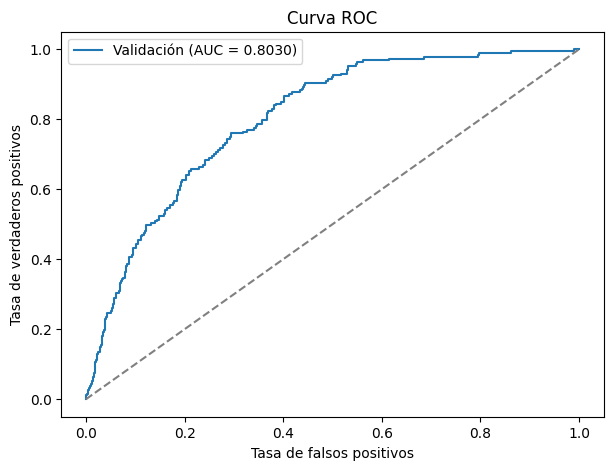

In [19]:
auc_roc(model_1)

#### Random Forest

In [20]:
model_2 = RandomForestClassifier(
    max_depth=10,
    random_state=seed,
)
model_2.fit(
    train_features, train_target
)

RandomForestClassifier(max_depth=10, random_state=1234)

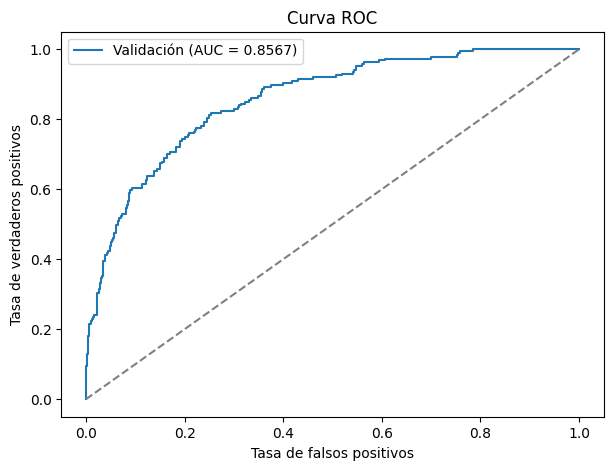

In [21]:
auc_roc(model_2) # La mejor alternativa de Random forest

In [22]:
model_3 = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=seed
)
model_3.fit(
    train_features, train_target
)

RandomForestClassifier(max_depth=10, n_estimators=200, random_state=1234)

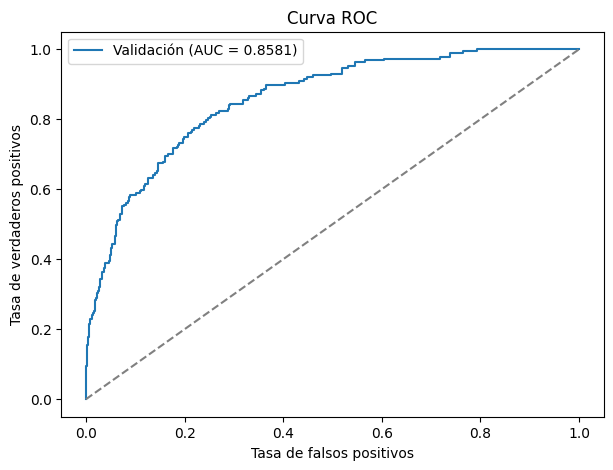

In [23]:
auc_roc(model_3)

In [24]:
model_4 = RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    random_state=seed
)
model_4.fit(
    train_features, train_target
)

RandomForestClassifier(max_depth=15, n_estimators=200, random_state=1234)

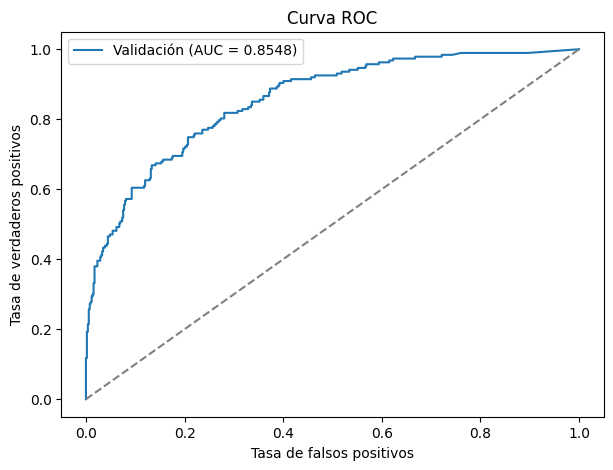

In [25]:
auc_roc(model_4)

#### XG Boost

In [26]:
def hyper_params_test(
    model,
    train_features,
    train_target,
    val_features,
    val_target,
    depths,
    n_estimators,
    learning_rates,
    dif_threshold,
    objective
):

    best_score = 0
    best_params = None
    best_proba = None
    best_difference = None

    for depth in depths:
        for n in n_estimators:
            for learning in learning_rates:

                clf = model(
                    n_estimators=n,
                    max_depth=depth,
                    learning_rate=learning,
                    random_state=seed,
                    eval_metric="auc",
                    use_label_encoder=False
                )

                clf.fit(train_features, train_target)

                proba = clf.predict_proba(val_features)[:, 1]

                score = roc_auc_score(val_target, proba)
                train_score = roc_auc_score(
                    train_target,
                    clf.predict_proba(train_features)[:, 1]
                )

                difference = train_score - score

                print(
                    f"Params: ({depth}, {n}, {learning})",
                    "----- AUC_ROC:", round(score, 4),
                    "----- Train:", round(train_score, 4),
                    "----- Valid:", round(score, 4),
                    "----- Diferencia:", round(difference, 4)
                )

                if score > best_score and difference <= dif_threshold:
                    best_score = score
                    best_params = (depth, n, learning)
                    best_proba = proba
                    best_difference = difference

                if score >= objective and difference <= dif_threshold:
                    return best_params, best_score, best_proba, best_difference

    return best_params, best_score, best_proba, best_difference

In [27]:
best_params, best_score, best_proba, difference = hyper_params_test(
    XGBClassifier,
    train_features,
    train_target,
    valid_features,
    valid_target,
    depths=[4, 6, 8],
    n_estimators=[300, 600, 900],
    learning_rates=[0.01, 0.1, 0.15],
    dif_threshold=0.05, # Este parametro es el umbral de la diferencias de score de train vs valid (entre más cercano a 0 indica mayor consistencia)
    objective=0.9 # Si consigue este score se detiene
)

print("\nMejores parámetros:", best_params)
print("Mejor AUC-ROC:", round(best_score, 4))
print("Diferencía del mejor resultado", round(difference, 4))

Params: (4, 300, 0.01) ----- AUC_ROC: 0.8737 ----- Train: 0.9067 ----- Valid: 0.8737 ----- Diferencia: 0.033
Params: (4, 300, 0.1) ----- AUC_ROC: 0.9232 ----- Train: 0.9855 ----- Valid: 0.9232 ----- Diferencia: 0.0622
Params: (4, 300, 0.15) ----- AUC_ROC: 0.9303 ----- Train: 0.9937 ----- Valid: 0.9303 ----- Diferencia: 0.0634
Params: (4, 600, 0.01) ----- AUC_ROC: 0.892 ----- Train: 0.9276 ----- Valid: 0.892 ----- Diferencia: 0.0356
Params: (4, 600, 0.1) ----- AUC_ROC: 0.9313 ----- Train: 0.9973 ----- Valid: 0.9313 ----- Diferencia: 0.066
Params: (4, 600, 0.15) ----- AUC_ROC: 0.9315 ----- Train: 0.9997 ----- Valid: 0.9315 ----- Diferencia: 0.0682
Params: (4, 900, 0.01) ----- AUC_ROC: 0.9016 ----- Train: 0.9407 ----- Valid: 0.9016 ----- Diferencia: 0.0391

Mejores parámetros: (4, 900, 0.01)
Mejor AUC-ROC: 0.9016
Diferencía del mejor resultado 0.0391


In [28]:
best_params_1, best_score_1, best_proba_1, difference_1 = hyper_params_test(
    XGBClassifier,
    train_features,
    train_target,
    valid_features,
    valid_target,
    depths=[3, 4],
    n_estimators=[1000, 1100, 1200],
    learning_rates=[0.008, 0.009],
    dif_threshold=0.03, # Este parametro es el umbral de la diferencias de score de train vs valid (entre más cercano a 0 indica mayor consistencia)
    objective=0.9 # Si consigue este score se detiene
)

print("\nMejores parámetros:", best_params_1)
print("Mejor AUC-ROC:", round(best_score_1, 4))
print("Diferencía del mejor resultado", round(difference_1, 4))

Params: (3, 1000, 0.008) ----- AUC_ROC: 0.8886 ----- Train: 0.9169 ----- Valid: 0.8886 ----- Diferencia: 0.0283
Params: (3, 1000, 0.009) ----- AUC_ROC: 0.8908 ----- Train: 0.9195 ----- Valid: 0.8908 ----- Diferencia: 0.0287
Params: (3, 1100, 0.008) ----- AUC_ROC: 0.8906 ----- Train: 0.919 ----- Valid: 0.8906 ----- Diferencia: 0.0284
Params: (3, 1100, 0.009) ----- AUC_ROC: 0.8928 ----- Train: 0.9224 ----- Valid: 0.8928 ----- Diferencia: 0.0296
Params: (3, 1200, 0.008) ----- AUC_ROC: 0.8925 ----- Train: 0.9214 ----- Valid: 0.8925 ----- Diferencia: 0.0289
Params: (3, 1200, 0.009) ----- AUC_ROC: 0.8944 ----- Train: 0.9245 ----- Valid: 0.8944 ----- Diferencia: 0.0302
Params: (4, 1000, 0.008) ----- AUC_ROC: 0.8993 ----- Train: 0.9364 ----- Valid: 0.8993 ----- Diferencia: 0.0371
Params: (4, 1000, 0.009) ----- AUC_ROC: 0.9017 ----- Train: 0.9405 ----- Valid: 0.9017 ----- Diferencia: 0.0388
Params: (4, 1100, 0.008) ----- AUC_ROC: 0.9014 ----- Train: 0.9391 ----- Valid: 0.9014 ----- Diferencia: 

In [29]:
# Comprobación de parametros con grafica AUC-ROC
model_5 = XGBClassifier(
    n_estimators=best_params_1[1],
    max_depth=best_params_1[0],
    learning_rate=best_params_1[2],
    random_state=seed,
    eval_metric="auc",
    use_label_encoder=False
)
model_5.fit(
    train_features, train_target
)

XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, enable_categorical=False,
              eval_metric='auc', gamma=0, gpu_id=-1, importance_type=None,
              interaction_constraints='', learning_rate=0.009, max_delta_step=0,
              max_depth=3, min_child_weight=1, missing=nan,
              monotone_constraints='()', n_estimators=1100, n_jobs=8,
              num_parallel_tree=1, predictor='auto', random_state=1234,
              reg_alpha=0, reg_lambda=1, scale_pos_weight=1, subsample=1,
              tree_method='exact', use_label_encoder=False,
              validate_parameters=1, verbosity=None)

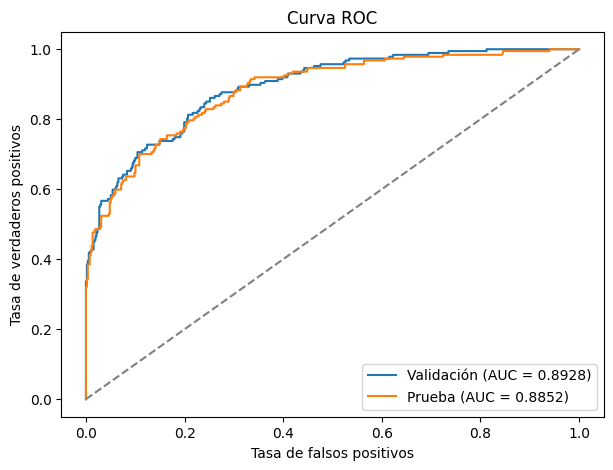

In [30]:
auc_roc(
    model_5,
    test_target=test_target,
    test_features=test_features
)

*Usando XGBoost con:* 
- n_estimators=$1100$
- max_depth=$3$
- learning_rate=$0.009$

se obtiene un AUC-ROC superior a lo solicitado de *$0.8928$*.

#### Red Neuronal 

In [31]:
def nn():
    tf.random.set_seed(seed)
    model = Sequential()
    
    model.add(Dense(16, activation='relu', input_shape=(train_features.shape[1],)))
    model.add(Dense(8, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(
        optimizer=Adam(learning_rate=0.005),
        loss='binary_crossentropy',
        metrics=[AUC(name='auc')]
    )
    return model

In [32]:
def nn_model_fit(model, class_weight=False):

    early_stop = EarlyStopping(
        monitor='val_auc',
        mode='max',
        patience=15,
        restore_best_weights=True
    )
    
    nn_history = model.fit(
        train_features,
        train_target,
        validation_data=(valid_features, valid_target),
        epochs=100,
        batch_size=32,
        callbacks=[early_stop],
        verbose=1,
        class_weight=class_weight
    )
    
    aucroc_score = max(
        nn_history.history['val_auc']
    )
    
    train_loss, train_auc = model.evaluate(
        train_features, train_target, verbose=0
    )
    
    valid_loss, valid_auc = model.evaluate(
        valid_features, valid_target, verbose=0
    )
    
    print("AUC-ROC:", round(aucroc_score, 4))
    print("Train:", round(train_auc, 4))
    print("Valid:", round(valid_auc, 4))
    print("Diferencia:", round(train_auc - valid_auc, 4))

    return nn_history

In [33]:
model_6 = nn()
nn_history = nn_model_fit(model_6, class_weight=False)

2026-11-03 08:07:56.719423: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Epoch 1/100
177/177 [==============================] - 1s 2ms/step - loss: 0.4651 - auc: 0.7961 - val_loss: 0.4765 - val_auc: 0.7899
Epoch 2/100
177/177 [==============================] - 0s 881us/step - loss: 0.4217 - auc: 0.8404 - val_loss: 0.4612 - val_auc: 0.8009
Epoch 3/100
177/177 [==============================] - 0s 885us/step - loss: 0.4159 - auc: 0.8449 - val_loss: 0.4648 - val_auc: 0.8016
Epoch 4/100
177/177 [==============================] - 0s 878us/step - loss: 0.4109 - auc: 0.8490 - val_loss: 0.4644 - val_auc: 0.8037
Epoch 5/100
177/177 [==============================] - 0s 882us/step - loss: 0.4083 - auc: 0.8515 - val_loss: 0.4604 - val_auc: 0.8057
Epoch 6/100
177/177 [==============================] - 0s 862us/step - loss: 0.4057 - auc: 0.8534 - val_loss: 0.4664 - val_auc: 0.8090
Epoch 7/100
177/177 [==============================] - 0s 869us/step - loss: 0.4000 - auc: 0.8582 - val_loss: 0.4603 - val_auc: 0.8108
Epoch 8/100
177/177 [==============================] - 0s

In [36]:
# Comprobación con conjunto de prueba
test_proba_6 = model_6.predict(test_features).ravel()

test_auc_6 = roc_auc_score(test_target, test_proba_6)

print("AUC-ROC Test:", round(test_auc_6, 4))

AUC-ROC Test: 0.9368


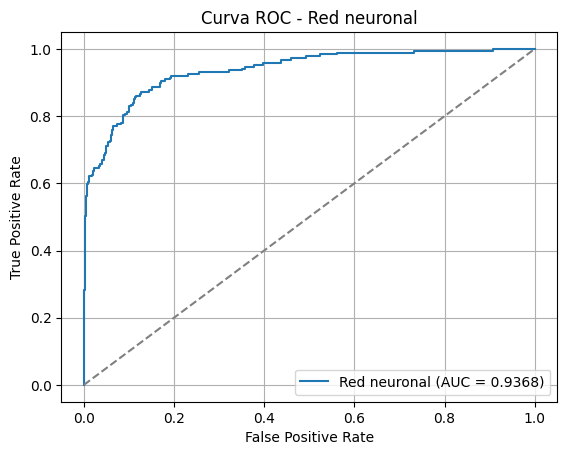

In [37]:
# Probabilidades de la red neuronal
proba = model_6.predict(test_features).ravel()

# Calcular curva ROC
fpr, tpr, _ = roc_curve(test_target, proba)
auc = roc_auc_score(test_target, proba)

# Graficar
plt.plot(fpr, tpr, label=f'Red neuronal (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], '--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC - Red neuronal')
plt.legend()
plt.grid()
plt.show()

*La red neuronal de Sequential con 55 epochs logro un mejor resultado de lo solicitado y además supero por bastante a los otros modelos, destacandose sobre los mismos con un AUC de $0.9368$ para test*


### 4. Optimización y Manejo de Desbalance
*Aplica al menos una técnica para manejar el desbalance de clases (upsampling, downsampling, o ajuste de pesos) y busca los mejores hiperparámetros. Evalúa nuevamente.*

In [38]:
# Ajuste de pesos
classes = np.unique(train_target)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=np.ravel(train_target)
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{0: 0.6805991785455424, 1: 1.8842809364548494}


In [39]:
# Creación y ajuste de modelo usando class_weights
model_7 = nn()
nn_model_fit(model_7, class_weight=class_weights)

Epoch 1/100
177/177 [==============================] - 1s 2ms/step - loss: 0.5377 - auc: 0.8033 - val_loss: 0.5796 - val_auc: 0.7990
Epoch 2/100
177/177 [==============================] - 0s 933us/step - loss: 0.4872 - auc: 0.8425 - val_loss: 0.5538 - val_auc: 0.8091
Epoch 3/100
177/177 [==============================] - 0s 928us/step - loss: 0.4807 - auc: 0.8476 - val_loss: 0.5081 - val_auc: 0.8071
Epoch 4/100
177/177 [==============================] - 0s 938us/step - loss: 0.4746 - auc: 0.8513 - val_loss: 0.4969 - val_auc: 0.8049
Epoch 5/100
177/177 [==============================] - 0s 921us/step - loss: 0.4745 - auc: 0.8516 - val_loss: 0.5602 - val_auc: 0.8118
Epoch 6/100
177/177 [==============================] - 0s 937us/step - loss: 0.4677 - auc: 0.8564 - val_loss: 0.5448 - val_auc: 0.8147
Epoch 7/100
177/177 [==============================] - 0s 930us/step - loss: 0.4620 - auc: 0.8608 - val_loss: 0.5221 - val_auc: 0.8145
Epoch 8/100
177/177 [==============================] - 0s

In [41]:
#AUC de validación
proba = model_7.predict(valid_features).ravel()
print("AUC validación:", roc_auc_score(valid_target, proba))

AUC validación: 0.911976747794247


In [42]:
def metricas_nn(model, features=valid_features, target=valid_target):
    proba = model.predict(features).ravel()
    pred = (proba >= 0.5).astype(int)

    print(classification_report(target, pred))

In [43]:
metricas_nn(model_6) # NN sin class_weights

              precision    recall  f1-score   support

           0       0.90      0.95      0.93       517
           1       0.84      0.72      0.77       187

    accuracy                           0.89       704
   macro avg       0.87      0.83      0.85       704
weighted avg       0.89      0.89      0.88       704



In [44]:
metricas_nn(model_7) # NN con class_weights

              precision    recall  f1-score   support

           0       0.92      0.86      0.89       517
           1       0.67      0.80      0.73       187

    accuracy                           0.84       704
   macro avg       0.80      0.83      0.81       704
weighted avg       0.85      0.84      0.85       704



*El ajuste de pesos mejoró el recall de la clase 1 de 0.72 a 0.80, permitiendo detectar aproximadamente 15 abandonos adicionales. Sin embargo, los falsos positivos aumentaron de 26 a 74, mientras que el AUC-ROC disminuyó de $0.9306$ a $0.9120$.*

*Por ello, se seleccionó el modelo sin ajuste de pesos (`model_6`), que ofrece un mejor equilibrio entre rendimiento predictivo y falsas alarmas, evitando acciones comerciales innecesarias.*


## Etapa 3: Informe de Solución
*Escribe aquí tu informe final para el equipo de negocio. Asegúrate de responder:*
1. *¿Qué modelo elegiste finalmente y por qué?*
2. *¿Cuáles fueron las métricas finales (AUC-ROC y Recall) en el conjunto de prueba?*
3. *En términos de negocio: ¿Qué significa tu valor de Recall? ¿Cómo impactaría tu modelo en la retención de clientes si el equipo de marketing lo utiliza hoy?*


**Despúes de evaluar algunos buenos modelos obtuve los siguientes resultados:**
- LogisticRegression: $0.8030$
- RandomForestClassifier: $0.8581$
- XGBClassifier: $0.8928$ y $0.0296$ de diferencia
- Sequential: $0.9306$ y $0.0339$ de diferencia

Opte por usar la red neuronal de Sequential por sus sobresalientes resultados que además en test obtuvieron $0.9368$.

### Metricas finales del conjunto de prueba
AUC-ROC: 0.9368

In [45]:
metricas_nn(model_6, test_features, test_target) # NN sin class_weights con conjunto de prueba

              precision    recall  f1-score   support

           0       0.92      0.93      0.92       518
           1       0.80      0.77      0.78       187

    accuracy                           0.89       705
   macro avg       0.86      0.85      0.85       705
weighted avg       0.89      0.89      0.89       705



*Recall: Para la clase 1 nos habla de que tantos de los usuarios que cancelaron fueron detectados por el modelo, mientras que para la clase 0 nos habla de cuantos de los detectados como "No cancela" realmente no cancelaron, es decir que nos habla de los verdaderos.*

*Un recall de $0.93$ para los clientes que no cancelan es excelente, ya que estos nos dice que solo se clasifica al 7% de los clientes que no van a cancelar de forma incorrecta, marcandolos como que si van a cancelar, mientras el recall de $0.77$ para los que si cancelan es muy interesante ya que se detectan casi 8 de cada 10 clientes que van a cancelar, permitiendo al equipo de marketing tomar accionespara prevenirlo.*

*La exactitud (accuracy) de 0.89 indica que el modelo clasifica correctamente al $89$% de los clientes del conjunto de prueba*